# 2차 실험 리포트: 생성기 일반화 · 강건성 · 보정 사진 오탐

1차 EfficientNetV2S 모델(ID Test 정확도 97.8%)에서 출발해, **처음 보는 생성기를 잡을 수 있는가**, **SNS 이미지(압축·축소)에서도 버티는가**,
**보정한 진짜 사진을 FAKE 로 오판하지 않는가**를 차례로 확인한 결과입니다. 이 노트북은 저장된 결과만 읽어서 보여줍니다.

| 한 줄 요약 | |
|---|---|
| 1차 결과의 한계 | "OOD" FLUX·SDXL 이 학습에 포함, test real 73% 가 train 과 같은 사진 → 진짜 일반화는 측정되지 않았음 |
| 모델만 바꾸기 (P3) | EfficientNetV2S · ConvNeXt-T · CLIP 모두 처음 보는 생성기 계열은 거의 못 잡음 |
| 증강 (P5) | 효과 없음. 오히려 구도 지름길이 지워져 diffusion OOD AUC 하락 |
| 의사 fake (P6) | real 만으로 만든 가짜(VAE 재구성 + SBI)로 처음 보는 diffusion AUC 0.872 → **0.965** |
| 강건성 (P7) | 축소·블러 증강으로 0.5배 축소 AUC 0.884 → **0.984** |
| 보정 사진 (실험 B) | SBI 가 피부 보정 real 을 FAKE 로 만듦(57~81%). SBI 를 빼면 **5~6%** |
| 배포 모델 (P7b) | **ConvNeXt-T + VAE + 축소·블러** (보정 오탐↓, 처음 보는 FLUX 탐지는 약해짐) |

자세한 설계·결정 과정은 `docs/EXPERIMENT_PLAN.md`, 실행 스크립트는 `scripts/`, 데모는 Windows 저장소 `server/`·`extension/` 입니다.

**목차**
1. 1차 결과와 데이터 문제
2. Phase 1 — 1차 모델 강건성
3. Phase 2 — 생성기 계열 단위 LOGO split, 파일 형식·구도 지름길
4. Phase 3 — 모델 비교
5. Phase 5 — 데이터 증강
6. Phase 6 — 의사 fake
7. Phase 7 — 최종 모델과 강건성 (실험 A)
8. 실험 B — 보정 사진 오탐과 Grad-CAM/ELA
9. Phase 7b — 배포 모델 결정
10. 결론과 한계

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

EXP2 = Path('../outputs/exp2')
REPORT = EXP2 / 'summary' / 'report'
pd.options.display.float_format = '{:.3f}'.format
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. 1차 결과와 데이터 문제

1차 EfficientNetV2S: ID Test 정확도 97.8% / AUC 0.998, GRAVEX 91.7%, FLUX·SDXL 99.6%. 하지만 데이터를 다시 확인해 보니

- **FLUX·SDXL 은 OOD 가 아니었습니다.** train 에 클래스별 36,800장 포함.
- **같은 사진이 여러 소스·split 에 중복**되어 있었습니다. real 183,700장 중 FFHQ 고유 사진은 70,000장뿐이고,
  1차 test real 의 **73%**, fake 의 **32%** 가 train 에도 있는 같은 사진입니다.
- 생성기마다 real 출처·파일 형식이 달라 **지름길 학습** 위험이 있었습니다.

그래서 1차 수치는 "외운 사진이 섞인, 학습한 생성기에 대한 성능"이고, 2차 실험은 이를 바로잡는 데서 시작했습니다.

## 2. Phase 1 — 1차 모델 강건성 (재학습 없음)

1차 모델에 JPEG 재압축·축소·블러를 적용했습니다(1차 test 26,876장, threshold 0.24). 상세: `notebooks/01_robustness_report.ipynb`.

In [2]:
rob = pd.read_csv(EXP2 / 'robustness' / 'robustness_summary.csv')
rob = rob[rob.subset == 'all'][['perturbation', 'accuracy', 'roc_auc_real_positive', 'fake_recall', 'real_recall']]
rob.columns = ['변환', '정확도', 'AUC', 'fake recall', 'real recall']
rob.set_index('변환')

,정확도,AUC,fake recall,real recall
변환,,,,
none,0.978,0.998,0.964,0.991
jpeg_q90,0.975,0.998,0.964,0.985
jpeg_q70,0.973,0.997,0.962,0.984
jpeg_q50,0.966,0.996,0.961,0.971
resize_0.75,0.977,0.998,0.967,0.988
resize_0.5,0.970,0.996,0.961,0.979
blur_0.5,0.978,0.998,0.966,0.990
blur_1.0,0.973,0.997,0.965,0.982


- 압축·축소에 꽤 강건하고(JPEG q50 에서 정확도 −1.2%p), 떨어지는 쪽은 **real** 입니다(SNS 진짜 사진이 FAKE 로 뜨는 방향).
- GRAVEX 에서 놓친 fake 의 67% 는 **FaceForensics++ 부분 조작**(98% 놓침)이었습니다. "통째로 생성한 얼굴"과 "영상 얼굴 조작"은 다른 과제입니다.

## 3. Phase 2 — LOGO split 과 지름길 점검

생성기 **계열**(gan / diffusion / manip) 하나를 학습에서 완전히 빼고, 뺀 계열로만 OOD 테스트합니다.
같은 사진·같은 영상 묶음은 한 split 에만 들어가도록 중복을 제거했고, 실행마다 누수 검사를 합니다.

In [3]:
split = pd.read_csv(EXP2 / 'logo_splits' / 'split_summary.csv')
split.pivot_table(index=['holdout', 'role'], columns=['label', 'family'], values='images', aggfunc='sum', fill_value=0)

label                   fake                 real
family             diffusion    gan  manip   real
holdout   role                                   
diffusion test_id          0   2512    488   3000
          test_ood     10000      0      0  10000
          train            0  24827   5173  30000
          valid            0   4003    997   5000
gan       test_id       2197      0    803   3000
          test_ood         0  10000      0  10000
          train        21379      0   8621  30000
          valid         3410      0   1590   5000
manip     test_id       1042   1958      0   3000
          test_ood         0      0  10000  10000
          train        10220  19780      0  30000
          valid         1741   3259      0   5000

**파일 형식 지름길.** 이미지 내용 없이 파일 정보(PNG 여부·JPEG 양자화 테이블·파일 크기)만으로 real/fake 를 맞혀 봤습니다.

In [4]:
probe = pd.read_csv(EXP2 / 'logo_splits' / 'shortcut_probe.csv').set_index('setup')
probe

,test_id_accuracy,test_id_auc,test_ood_accuracy,test_ood_auc
setup,,,,
1차 데이터,0.678,0.772,NaN,NaN
LOGO-gan,0.896,0.970,0.505,0.528
LOGO-diffusion,0.690,0.752,0.713,0.831
LOGO-manip,0.740,0.854,0.517,0.556


파일 정보만으로 최대 **90%** 를 맞힐 수 있어서, 이후 모든 학습·평가는 이미지를 읽은 뒤 **같은 방식으로 JPEG 재인코딩**합니다
(학습 품질 60~95 무작위, 평가 90 고정).

**구도 지름길.** 얼굴이 이미지에서 차지하는 비율이 생성기마다 다릅니다(데모와 같은 얼굴 검출기로 측정).

In [5]:
size = pd.read_csv(EXP2 / 'framing_shortcut' / 'face_size_stats.csv')
size['label'] = size['label'].map({0: 'fake', 1: 'real'})
display(size.pivot(index='source', columns='label', values='50%').rename_axis(None, axis=1).add_prefix('얼굴 비율 중앙값 · '))
framing = pd.read_csv(EXP2 / 'framing_shortcut' / 'framing_only_classifier.csv').set_index('source')
framing

,얼굴 비율 중앙값 · fake,얼굴 비율 중앙값 · real
source,,
flux_sdxl,0.355,0.598
gravex,0.609,0.605
stylegan,0.600,0.598


,n,framing_only_acc,framing_only_auc
source,,,
flux_sdxl,798,0.969,0.990
gravex,796,0.582,0.601
stylegan,800,0.516,0.521
ALL,2394,0.641,0.682


FLUX·SDXL fake 는 얼굴이 작게(0.36), FFHQ real 은 크게(0.60) 찍혀 있어서 **얼굴 위치·크기만으로 AUC 0.99** 가 나옵니다.
그래서 Phase 5 부터는 데모와 같은 **얼굴 crop x2.0 보기**로도 평가합니다.

## 4. Phase 3 — 모델 비교 (3 모델 × LOGO 3종)

| 모델 | 방식 |
|---|---|
| EfficientNetV2S | 전체 fine-tuning (1차와 같은 구조) |
| ConvNeXt-T | 전체 fine-tuning |
| CLIP ViT-L/14 + 선형 | 백본 고정 (UnivFD, CVPR 2023) |

,ID Macro F1,OOD gan (F1 / AUC),OOD diffusion (F1 / AUC),OOD manip (F1 / AUC),OOD 평균 (F1 / AUC),JPEG q50 Macro F1
모델,,,,,,
EfficientNetV2S,0.978,0.333 / 0.474,0.342 / 0.692,0.414 / 0.442,0.363 / 0.536,0.971
ConvNeXt-T,0.982,0.333 / 0.377,0.337 / 0.871,0.423 / 0.433,0.365 / 0.560,0.978
CLIP + Linear,0.942,0.393 / 0.785,0.339 / 0.308,0.491 / 0.553,0.408 / 0.549,0.911


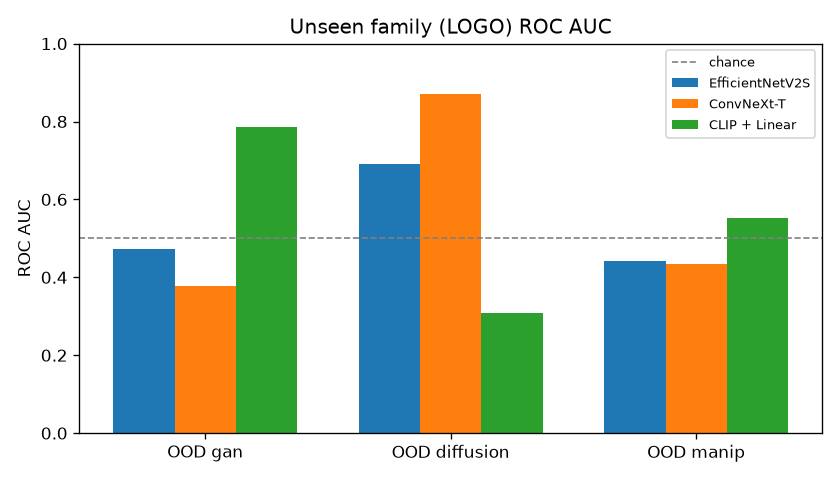

In [6]:
display(pd.read_csv(EXP2 / 'summary' / 'final_table.csv').set_index('모델'))
display(Image(EXP2 / 'summary' / 'ood_auc.png', width=640))

- 학습한 계열은 세 모델 모두 잘 잡지만(ID Macro F1 0.94~0.98), **처음 보는 계열은 모두 거의 못 잡습니다**(OOD F1 0.333 = 전부 REAL 예측).
- ConvNeXt-T 의 diffusion AUC 0.871 처럼 순위는 맞아도, valid threshold 에서는 fake recall 이 0.4% 입니다.
- CLIP 이 새 생성기에 강하다는 보고는 이 조건(중복 제거·형식 정규화)에서 일관되게 재현되지 않았습니다.
- **결론:** 모델 교체만으로는 일반화가 풀리지 않음 → 기존 데이터로 할 수 있는 방법(Phase 5~7)을 시도했습니다.

## 5. Phase 5 — 데이터 증강

얼굴 crop 배율 무작위(1.4~3.0) + SNS 열화(축소·블러/샤픈·색·피부 스무딩·JPEG 40~95) + 생성기 균형 샘플링.

In [7]:
runs = pd.read_csv(REPORT / 'runs_by_view.csv')
p5 = runs[runs.phase.isin(['P3 baseline', 'P5']) & (runs.holdout != 'all') & (runs.view == 'crop')]
p5.pivot(index='model', columns='holdout', values='ood_auc').loc[
    ['EfficientNetV2S', 'EfficientNetV2S + strong aug', 'ConvNeXt-T', 'ConvNeXt-T + strong aug']].add_prefix('OOD AUC · ')

holdout,OOD AUC · diffusion,OOD AUC · gan,OOD AUC · manip
model,,,
EfficientNetV2S,0.728,0.473,0.458
EfficientNetV2S + strong aug,0.678,0.480,0.438
ConvNeXt-T,0.872,0.376,0.473
ConvNeXt-T + strong aug,0.683,0.502,0.442


증강은 **효과가 없었습니다.** 방해 단서를 지울 뿐 새 생성기의 흔적을 알려주지는 못하고,
diffusion AUC 가 내려간 것(0.872 → 0.683)은 기준선 점수 일부가 구도 지름길에서 나왔다는 뜻입니다.

## 6. Phase 6 — 의사 fake (pseudo-fake)

real 사진만으로 "가짜 예시"를 만들어 fake 로 추가합니다(각각 real train 의 50%).
- **VAE 재구성** (Rajan et al., ICLR 2025): real 을 SD VAE 로 인코딩·디코딩. diffusion 디코더의 흔적만 남고 내용은 같습니다. 원본과 같은 JPEG 테이블로 저장.
- **SBI** (Shiohara & Yamasaki, CVPR 2022): 색·선명도·크기를 살짝 바꾼 자기 사본을 얼굴 타원 마스크로 다시 합성. 합성 경계 흔적을 배웁니다.

holdout,OOD AUC · diffusion,OOD AUC · gan,OOD AUC · manip,diffusion fake recall
model,,,,
ConvNeXt-T,0.872,0.376,0.473,0.010
ConvNeXt-T + VAE,0.952,0.537,0.517,0.209
ConvNeXt-T + SBI,0.929,0.353,0.506,0.233
ConvNeXt-T + VAE + SBI,0.965,0.489,0.508,0.585


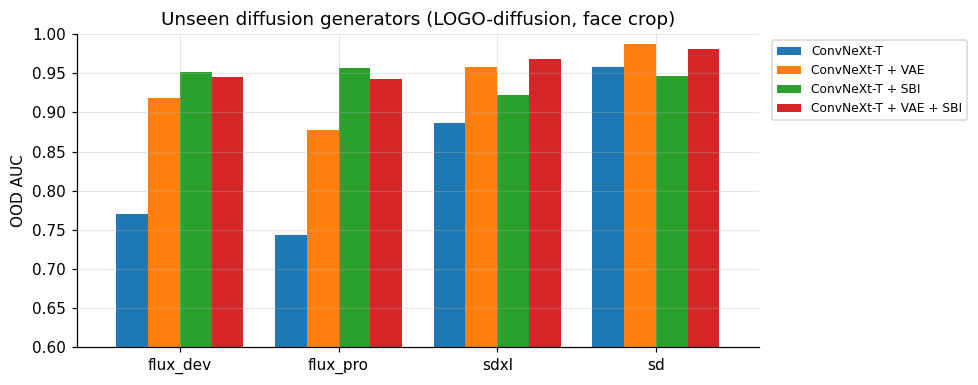

In [8]:
order = ['ConvNeXt-T', 'ConvNeXt-T + VAE', 'ConvNeXt-T + SBI', 'ConvNeXt-T + VAE + SBI']
p6 = runs[runs.model.isin(order) & (runs.view == 'crop') & (runs.holdout != 'all')]
table = p6.pivot(index='model', columns='holdout', values='ood_auc').loc[order].add_prefix('OOD AUC · ')
table['diffusion fake recall'] = p6[p6.holdout == 'diffusion'].set_index('model').loc[order, 'ood_fake_recall']
display(table)

gen = pd.read_csv(REPORT / 'diffusion_by_generator.csv')
gen = gen[gen.model.isin(order)].pivot(index='generator', columns='model', values='ood_auc')[order]
ax = gen.loc[['flux_dev', 'flux_pro', 'sdxl', 'sd']].plot.bar(figsize=(9, 3.6), rot=0, width=0.8)
ax.set(title='Unseen diffusion generators (LOGO-diffusion, face crop)', ylabel='OOD AUC', ylim=(0.6, 1.0), xlabel='')
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()

- **처음 보는 diffusion: AUC 0.872 → 0.965, fake recall 1% → 58.5%.** 2차 실험에서 일반화를 실제로 끌어올린 유일한 방법입니다.
- VAE 는 같은 VAE 디코더를 쓰는 SD·SDXL 에, SBI 는 FLUX 에 더 잘 일반화해서 둘을 합쳤을 때 가장 좋았습니다.
- GAN·영상 조작(manip)은 거의 그대로입니다. 두 방법 모두 그 흔적을 겨냥하지 않기 때문입니다.

## 7. Phase 7 — 최종 모델과 강건성 (실험 A 축소판)

세 LOGO split 의 train 을 합쳐 모든 계열로 학습하고, 학습에 안 쓴 **held-out 2만 장**으로 평가합니다(계열을 빼지 않았으므로 OOD 아님).
변환은 서버와 같은 순서(열화 → 얼굴 crop → JPEG 90)로 적용하고 threshold 는 고정입니다.

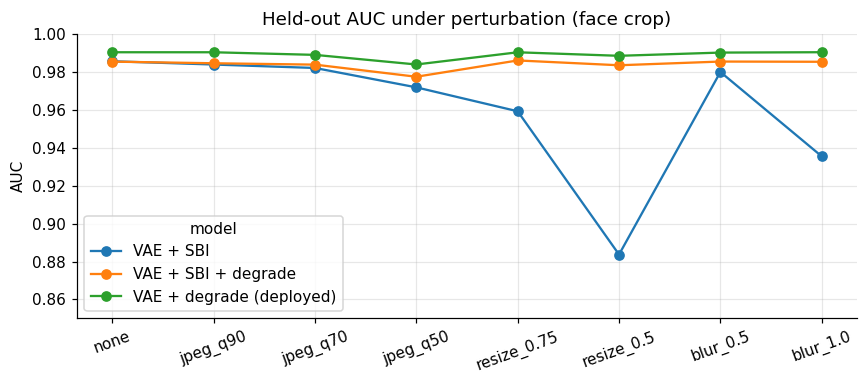

fake recall             VAE + SBI  VAE + SBI + degrade  \
family    perturbation                                   
diffusion blur_1.0          0.978                0.989   
          none              0.997                0.995   
          resize_0.5        0.995                0.995   
gan       blur_1.0          0.737                0.997   
          none              0.995                0.997   
          resize_0.5        0.646                0.987   
manip     blur_1.0          0.783                0.732   
          none              0.814                0.791   
          resize_0.5        0.870                0.846   

fake recall             VAE + degrade (deployed)  
family    perturbation                            
diffusion blur_1.0                         0.995  
          none                             0.996  
          resize_0.5                       0.993  
gan       blur_1.0                         0.996  
          none                             0.999  
          resize_0.5                       0.988  
manip     blur_1.0                         0.723  
          none                             0.775  
          resize_0.5                       0.721

In [9]:
rob = pd.read_csv(REPORT / 'final_robustness.csv')
rob = rob[(rob.view == 'face_crop') & (rob.eval_set == 'held_out')]
perts = ['none', 'jpeg_q90', 'jpeg_q70', 'jpeg_q50', 'resize_0.75', 'resize_0.5', 'blur_0.5', 'blur_1.0']
auc = rob.pivot(index='perturbation', columns='model', values='roc_auc_real_positive').loc[perts]
models = ['VAE + SBI', 'VAE + SBI + degrade', 'VAE + degrade (deployed)']
ax = auc[models].plot(marker='o', figsize=(8, 3.6))
ax.set(title='Held-out AUC under perturbation (face crop)', ylabel='AUC', xlabel='', ylim=(0.85, 1.0))
ax.set_xticks(range(len(perts))); ax.set_xticklabels(perts, rotation=20); plt.tight_layout(); plt.show()

fam = pd.read_csv(REPORT / 'final_robustness_by_family.csv')
fam = fam[(fam.view == 'face_crop') & (fam.eval_set == 'held_out') & fam.perturbation.isin(['none', 'resize_0.5', 'blur_1.0'])]
fam.pivot_table(index=['family', 'perturbation'], columns='model', values='fake_recall')[models].rename_axis(columns='fake recall')

- VAE+SBI 모델은 JPEG 에는 강했지만 **0.5배 축소에서 AUC 0.884, GAN fake recall 64.6%** 로 무너졌습니다. SNS 이미지는 대부분 축소돼 있습니다.
- 학습에 **축소(0.4~1.0x)·블러 증강**을 넣자 0.5배 축소에서도 AUC 0.984 로 유지됐습니다.
- 대가: diffusion 을 뺀 LOGO 실험에서 처음 보는 diffusion fake recall 0.585 → 0.245 (AUC 0.965 → 0.951).
- 영상 조작(manip)은 모든 모델에서 가장 약한 계열입니다(fake recall 약 75~85%).

## 8. 실험 B — 보정한 진짜 사진을 FAKE 로 오판하는가

학습에 안 쓴 FFHQ real 400장에 스크립트로 보정을 걸고(카메라 JPEG q90 → 보정 → 앱 JPEG q95), **데모 서버 코드 그대로** 판정했습니다.
보정 4종: 피부 보정(bilateral) · 눈 키우기 · 얼굴 슬림(턱선) · 뷰티 조합(전부 + 톤), 강도 1~3단계. 실행: Windows 저장소 `experiments/edited_photos.py`.

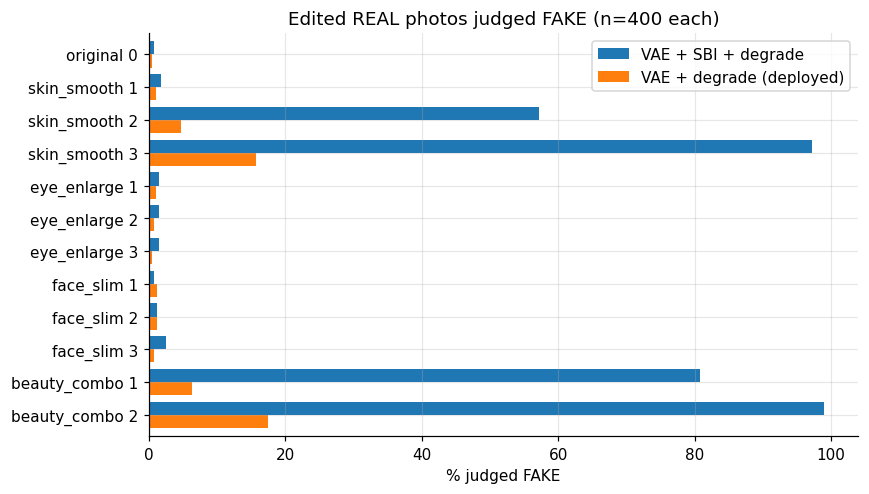

In [10]:
B = EXP2 / 'experiment_b'
cmp = pd.read_csv(B / 'vae_sbi_deg_vs_vae_deg.csv')
cmp['key'] = cmp.edit + ' ' + cmp.level.astype(str)
cmp = cmp.set_index('key')[['fake_rate_deployed', 'fake_rate_vae_deg']]
cmp.columns = ['VAE + SBI + degrade', 'VAE + degrade (deployed)']
ax = (cmp * 100).plot.barh(figsize=(8, 4.6), width=0.8)
ax.invert_yaxis(); ax.set(title='Edited REAL photos judged FAKE (n=400 each)', xlabel='% judged FAKE', ylabel='')
plt.tight_layout(); plt.show()

**원인 찾기.** 같은 보정 사진 150장을 의사 fake 조합만 다른 모델들로 판정했습니다(앞 4개는 diffusion 제외 LOGO 모델).

In [11]:
abl = pd.read_csv(B / 'fake_rate_by_model.csv').set_index('key')
abl.columns = ['LOGO baseline', 'LOGO + VAE', 'LOGO + SBI', 'LOGO + VAE + SBI', 'final VAE + SBI', 'final VAE + SBI + degrade']
(abl.loc[['original_0', 'skin_smooth_2', 'skin_smooth_3', 'beauty_combo_1', 'beauty_combo_2', 'eye_enlarge_3', 'face_slim_3']] * 100).round(1)

,LOGO baseline,LOGO + VAE,LOGO + SBI,LOGO + VAE + SBI,final VAE + SBI,final VAE + SBI + degrade
key,,,,,,
original_0,0.000,0.000,0.700,1.300,0.700,0.700
skin_smooth_2,0.000,3.300,62.700,68.700,57.300,56.700
skin_smooth_3,0.000,9.300,98.700,100.000,96.700,98.700
beauty_combo_1,0.000,3.300,86.700,90.000,87.300,81.300
beauty_combo_2,0.000,5.300,99.300,99.300,100.000,99.300
eye_enlarge_3,0.000,0.700,3.300,1.300,1.300,2.700
face_slim_3,0.000,0.000,2.700,2.700,3.300,2.700


- **피부를 매끄럽게 하는 보정은 SBI 가 들어간 모델에서만 FAKE 가 됩니다**(63~100%). SBI 는 "얼굴에 살짝 흐린 사본을 합성"하는 방식이라
  피부 보정과 같은 흔적을 fake 로 가르칩니다. 의사 fake 가 없거나 VAE 만 쓴 모델은 0~9% 입니다.
- 모양만 바꾸는 보정(눈·슬림)은 어느 모델이든 3% 이하입니다.

**Grad-CAM 과 ELA 는 보정 위치를 가리키는가.** 보정 마스크(원본과 보정본의 픽셀 차이)와 겹침을 쟀습니다.
Pointing = 맵의 최댓값이 마스크 안에 있는 비율. "항상 가운데"와 "무작위" 기준선을 함께 봐야 합니다.

In [12]:
ov = pd.read_csv(B / 'deployed_vae_sbi_deg_overlap.csv')
ov['key'] = ov.edit + ' ' + ov.level.astype(str)
ov.set_index('key')[['mask_area', 'cam_pointing', 'ela_pointing', 'center_pointing', 'chance_pointing', 'cam_iou_area', 'ela_iou_area']]

,mask_area,cam_pointing,ela_pointing,center_pointing,chance_pointing,cam_iou_area,ela_iou_area
key,,,,,,,
skin_smooth 1,0.011,0.170,0.510,0.357,0.127,0.008,0.094
skin_smooth 2,0.294,0.907,0.948,1.000,0.448,0.260,0.457
skin_smooth 3,0.367,0.935,0.945,1.000,0.482,0.313,0.424
eye_enlarge 1,0.038,0.340,0.677,0.217,0.073,0.069,0.395
eye_enlarge 2,0.045,0.410,0.705,0.412,0.082,0.091,0.419
eye_enlarge 3,0.049,0.450,0.718,0.550,0.086,0.103,0.436
face_slim 1,0.132,0.237,0.833,0.000,0.196,0.104,0.464
face_slim 2,0.153,0.357,0.873,0.003,0.215,0.148,0.485
face_slim 3,0.163,0.555,0.882,0.005,0.223,0.198,0.495


- **Grad-CAM 은 보정 위치를 알려주지 못합니다.** 넓은 보정(피부·뷰티)은 "항상 가운데" 기준선도 1.00 이라 의미가 없고, 국소 보정(눈·슬림)은 0.24~0.56 입니다.
  Grad-CAM 은 "모델이 본 곳"이지 "조작된 곳"이 아닙니다.
- **ELA 는 원본 파일에서는 국소 보정 위치를 잘 짚습니다**(눈 0.68~0.72, 슬림 0.83~0.88). SNS 재압축 후에는 확인하지 않았습니다.

**예시 (VAE + SBI + degrade 모델)**: 원본 / 보정본 / 보정 마스크 / Grad-CAM / ELA

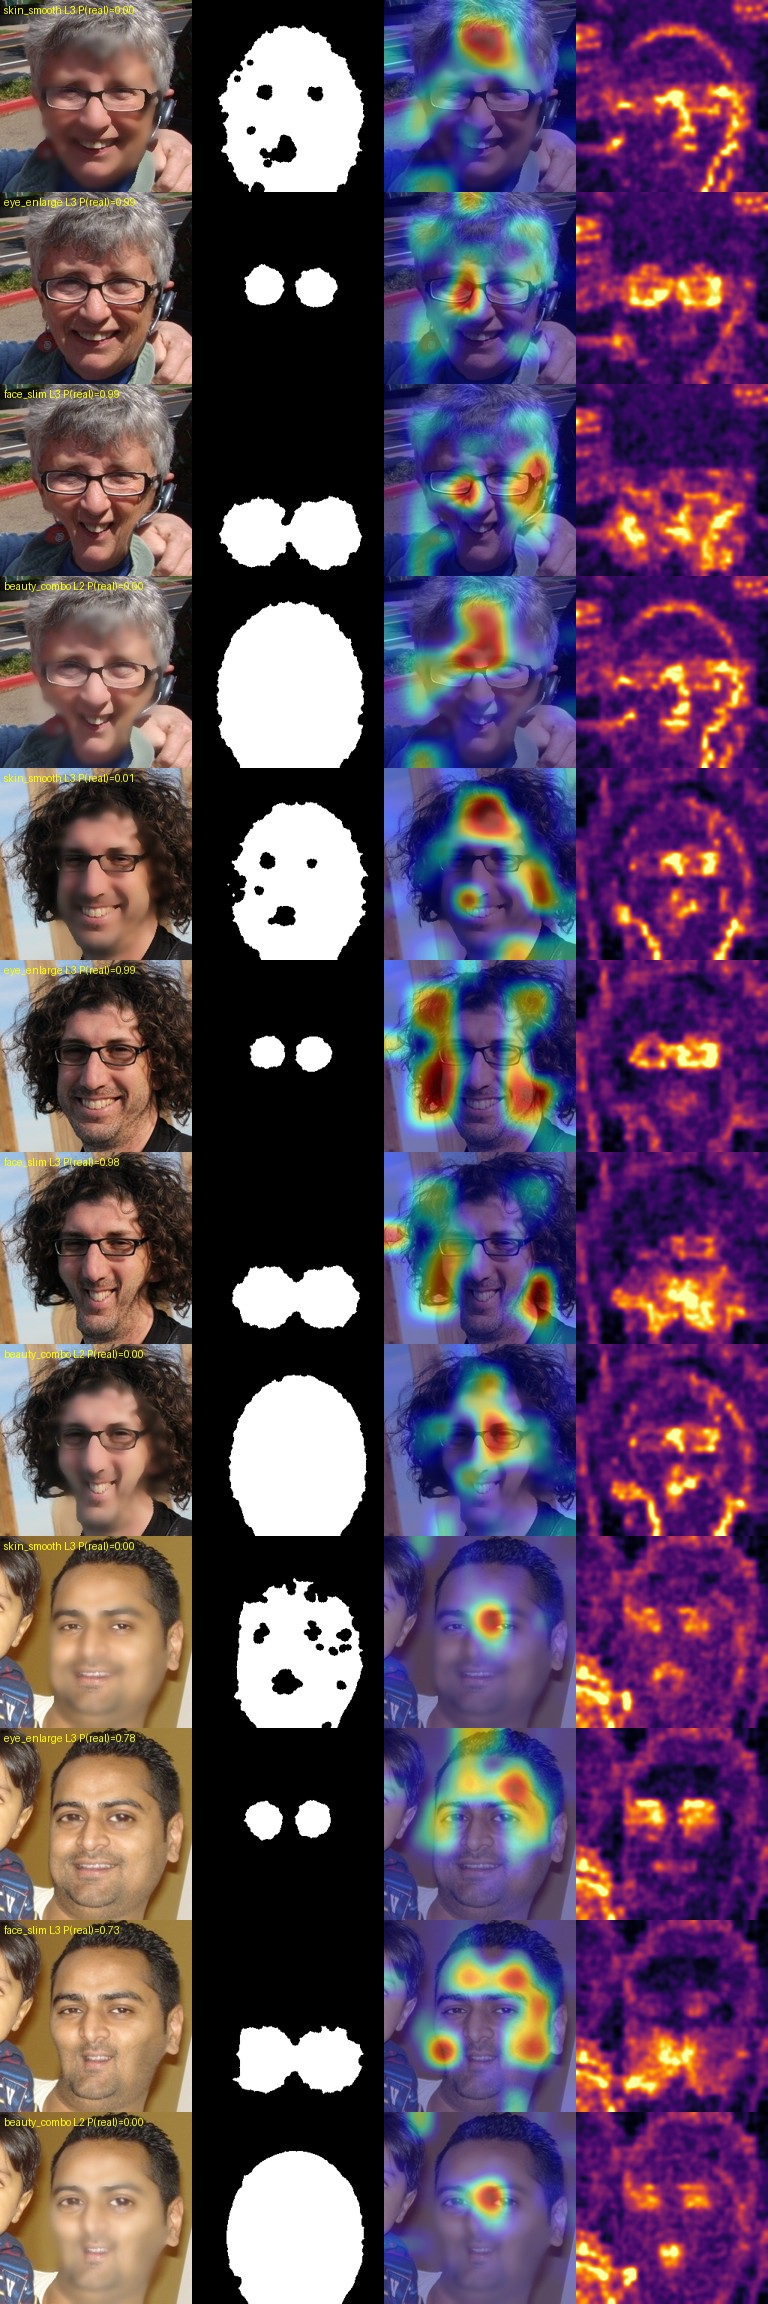

In [13]:
display(Markdown('**예시 (VAE + SBI + degrade 모델)**: 원본 / 보정본 / 보정 마스크 / Grad-CAM / ELA'))
display(Image(B / 'examples_vae_sbi_deg.jpg', width=900))

## 9. Phase 7b — 배포 모델 결정

실험 B 결과에 따라 SBI 를 빼고 Phase 7 과 같은 절차(VAE + 축소·블러)로 다시 학습했습니다.

In [14]:
final = runs[(runs.holdout == 'all') & (runs.view == 'crop') & runs.phase.isin(['P7', 'P7b'])].set_index('model')
logo = runs[(runs.holdout == 'diffusion') & (runs.view == 'crop') & runs.phase.isin(['P7', 'P7b'])].set_index('model')
gen_all = pd.read_csv(REPORT / 'diffusion_by_generator.csv').pivot(index='model', columns='generator', values='ood_auc')
edit = pd.read_csv(B / 'vae_sbi_deg_vs_vae_deg.csv').set_index(['edit', 'level'])
rb = rob.pivot(index='perturbation', columns='model', values='roc_auc_real_positive')
names = {'ConvNeXt-T + VAE + SBI + degrade': ('VAE + SBI + degrade', 'fake_rate_deployed'),
         'ConvNeXt-T + VAE + degrade': ('VAE + degrade (deployed)', 'fake_rate_vae_deg')}
rows = {}
for model, (rob_name, edit_col) in names.items():
    rows[model] = {
        'held-out AUC': final.loc[model, 'ood_auc'],
        'held-out real recall': final.loc[model, 'ood_real_recall'],
        'held-out AUC, resize 0.5': rb.loc['resize_0.5', rob_name],
        'held-out AUC, blur 1.0': rb.loc['blur_1.0', rob_name],
        '피부 보정 중 → FAKE': edit.loc[('skin_smooth', 2), edit_col],
        '뷰티 조합 중 → FAKE': edit.loc[('beauty_combo', 1), edit_col],
        'LOGO-diffusion OOD AUC': logo.loc[model, 'ood_auc'],
        '└ FLUX-dev': gen_all.loc[model, 'flux_dev'],
        '└ FLUX-pro': gen_all.loc[model, 'flux_pro'],
        'threshold (P(real))': final.loc[model, 'threshold'],
    }
pd.DataFrame(rows)

,ConvNeXt-T + VAE + SBI + degrade,ConvNeXt-T + VAE + degrade
held-out AUC,0.986,0.990
held-out real recall,0.918,0.954
"held-out AUC, resize 0.5",0.984,0.989
"held-out AUC, blur 1.0",0.985,0.990
피부 보정 중 → FAKE,0.573,0.048
뷰티 조합 중 → FAKE,0.807,0.062
LOGO-diffusion OOD AUC,0.951,0.925
└ FLUX-dev,0.941,0.881
└ FLUX-pro,0.941,0.804
threshold (P(real)),0.300,0.160


**결정 (2026-11-09): 배포 기본 = ConvNeXt-T + VAE + 축소·블러.**
- 학습한 계열 성능·축소/블러 강건성·real 오탐은 같거나 낫고, 보정 사진 오탐이 57~81% → **5~6%** 로 줄었습니다.
  인스타그램 사진은 피부 보정이 흔하므로 이쪽을 택했습니다.
- 대신 **처음 보는 FLUX** 탐지가 약해집니다(FLUX-pro AUC 0.94 → 0.80). SBI 는 "새 생성기 일반화"와 "보정 사진 오탐"을 맞바꾸는 방법입니다.
- 이전 모델은 데모 서버에 `convnext_tiny_fake_face_sbi.json` 으로 남겨 두었습니다.

## 10. 결론과 한계

**결론**
1. 1차 97.8% 는 중복 사진과 학습한 생성기가 섞인 값이었습니다. 엄격한 조건(계열 단위 분할·중복 제거·형식 정규화)에서는 **처음 보는 생성기 계열을 어떤 모델도 잘 잡지 못했습니다.**
2. 기존 데이터만으로 효과가 있었던 것은 **의사 fake** 입니다. VAE 재구성은 diffusion 일반화를 크게 높이고 부작용이 적었습니다.
3. SNS 환경에서는 **축소·블러 강건성**이 실제로 문제였고, 열화 증강으로 해결했습니다.
4. **SBI 는 피부 보정 사진을 FAKE 로 만드는 부작용**이 있어 배포 모델에서 뺐습니다.
5. Grad-CAM 은 판정 근거 시각화일 뿐 조작 위치를 알려주지 않습니다. ELA 가 국소 보정에는 더 잘 맞습니다.

**한계**
- 처음 보는 GAN·영상 딥페이크(manip) 계열은 어떤 방법으로도 거의 개선되지 않았습니다. manip 은 학습한 경우에도 fake recall 약 75~80% 입니다.
- 최신 상용 생성기(Midjourney 등)와 실제 앱 AI 뷰티 필터는 데이터가 없어 평가하지 못했습니다(새 데이터 수집은 보류).
- 대부분 시드 1회 결과입니다. 이미 픽셀에 남은 이중 압축 흔적까지 완전히 지울 수는 없습니다.

**재현**
```bash
source .venv-exp2/bin/activate
bash scripts/run_phase6.sh && bash scripts/run_phase7.sh && bash scripts/run_phase7b.sh
python scripts/52_eval_robustness_final.py --run convnext_tiny_pseudo_vae_deg
python scripts/41_summarize_final.py
.venv/bin/python scripts/42_build_final_report.py && .venv/bin/jupyter nbconvert --to notebook --execute --inplace notebooks/02_generalization_report.ipynb
```
실험 B 는 Windows 저장소에서 `python experiments/edited_photos.py` 로 실행하고, 요약 CSV 를 `outputs/exp2/experiment_b/` 에 복사했습니다.